# Qualcomm (QCOM) — FY2029 EV/EBITDA Valuation

| | |
|---|---|
| **Valuation date** | **September 1, 2026** |
| **Latest financials used** | **Q3 FY2026** — quarter ended June 28, 2026, reported July 29, 2026 |
| **Price anchor** | **$170.48** (Aug 31, 2026 close) |
| **Forward targets from** | June 24, 2026 Investor Day (FY29 targets reaffirmed at the Q3 print) |

**Sum-of-the-parts EV/EBITDA**, three scenarios (**Bear / Base / Bull**), discounted to a present value.

- **Base = management's FY29 revenue targets**, taken at face value. Margins are the author's — see the EPS cross-check in §8, which quantifies the gap.
- The whole thesis is that a low-multiple handset/licensing business is being diluted by higher-multiple automotive, IoT, and (especially) **data-center** businesses — so each segment is valued on its own peer set.
- See `README.md` for the company overview, the 2024-vs-2026 Investor Day comparison, and the multiple justifications.

> **Not investment advice.** All forward figures are management targets or author assumptions, not facts.

## 1. Assumptions

Everything the model needs is in the next cell — it mirrors the `ASSUMPTIONS` block in `model.py`.
Change a number, re-run the notebook, done.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Provenance -------------------------------------------------------------------
VALUATION_DATE = 'September 1, 2026'
LATEST_REPORT  = 'Q3 FY2026 - quarter ended June 28, 2026, reported July 29, 2026'
PRICE_DATE     = 'August 31, 2026'

# --- Market anchors ---------------------------------------------------------------
CURRENT_PRICE = 170.48  # Aug 31, 2026 close (was $250 in the June 2026 run)
SHARES_OUT    = 1.069   # billion, Q3 FY26 diluted (1,069M)
NET_DEBT      = 7.0     # $B: total debt $15.27B less cash+securities $8.30B
DISCOUNT_RATE = 0.10    # required annual return
YEARS_TO_FY29 = 3.08    # Sept 1, 2026 -> FY29 year-end (late Sept 2029)

# --- Reported FY2026 quarters ($M, as filed; Q4 = guidance midpoint) ---------------
FY26_QUARTERS = pd.DataFrame(
    [[12252, 10613, 3302, 1592, 1231, 7824, 1101, 1688],
     [10599,  9076, 2465, 1382,  994, 6024, 1326, 1726],
     [ 9947,  8504, 2192, 1278,  881, 5086, 1588, 1830],
     [10100,  8700, 2262, 1300,  897, 5100, 1700, 1900]],
    index=['Q1', 'Q2', 'Q3', 'Q4E'],
    columns=['total', 'qct', 'qct_ebt', 'qtl', 'qtl_ebt', 'handset', 'automotive', 'iot'])

FY26_D_AND_A = 1.6          # $B, full year (9M reported $1,202M)

# EBITDA = (QCT EBT + QTL EBT) - unallocated corporate + D&A, non-GAAP basis.
# Corporate bridge calibrated to Q3 FY26: segment EBT $3,073M vs reported
# non-GAAP EBT $2,693M -> $380M/qtr.
CORPORATE_PER_YEAR = 1.5    # $B
NON_GAAP_TAX_RATE  = 0.13
NET_INTEREST_FY29  = 0.5    # $B

# FY2025 actuals (year ended Sept 28, 2025), same EBITDA basis
FY25_REVENUE, FY25_QCT_EBT, FY25_QTL_EBT, FY25_D_AND_A = 44.284, 11.670, 4.044, 1.602

# --- Scenario inputs --------------------------------------------------------------
SEGMENTS = ['handset', 'automotive', 'iot', 'datacenter']

# FY29 revenue ($B). BASE = mgmt Investor-Day targets at face value (reaffirmed at Q3 FY26).
REVENUE = {
    'Bear': {'handset': 16, 'automotive':  8, 'iot': 10, 'datacenter':  9},
    'Base': {'handset': 20, 'automotive': 10, 'iot': 14, 'datacenter': 15},
    'Bull': {'handset': 23, 'automotive': 13, 'iot': 16, 'datacenter': 20},
}

# FY29 EBITDA margin. Base/Bull track the reaffirmed QCT ~30% / QTL ~70% targets.
# Bear is where 'input-cost inflation never normalizes' lives (Q3 FY26 QCT EBT: 26%).
EBITDA_MARGIN = {
    'Bear': {'handset': 0.32, 'automotive': 0.22, 'iot': 0.24, 'datacenter': 0.18},
    'Base': {'handset': 0.38, 'automotive': 0.28, 'iot': 0.30, 'datacenter': 0.25},
    'Bull': {'handset': 0.40, 'automotive': 0.30, 'iot': 0.33, 'datacenter': 0.30},
}

# FY29 exit EV/EBITDA multiple per segment (README section 6 for peer justification)
EXIT_MULTIPLE = {
    'Bear': {'handset':  7, 'automotive': 10, 'iot': 10, 'datacenter': 11},
    'Base': {'handset':  8, 'automotive': 13, 'iot': 13, 'datacenter': 18},
    'Bull': {'handset': 10, 'automotive': 16, 'iot': 18, 'datacenter': 25},
}

WEIGHTS = {'Bear': 0.25, 'Base': 0.50, 'Bull': 0.25}

MGMT_FY29_EPS = 18.0    # mgmt FY29 non-GAAP EPS target (>$18)
FY29_SHARES   = 1.02    # $B shares after ~1.5%/yr net buyback shrink
FY29_D_AND_A  = 1.8     # $B

# --- Chart palette ----------------------------------------------------------------
# Categorical slots (validated: adjacent CVD dE 9.1, normal-vision 22.9).
SEG_COLORS = {'handset': '#2a78d6', 'automotive': '#eb6834',
              'iot': '#1baf7a', 'datacenter': '#eda100'}
# Bear/Base/Bull is a polarity encoding -> diverging blue<->red with a neutral midpoint.
SCEN_COLORS = {'Bear': '#d03b3b', 'Base': '#6b6b66', 'Bull': '#2a78d6'}
INK, GRID = '#0b0b0b', '#d8d7d2'

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': GRID, 'text.color': INK,
                     'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK,
                     'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
                     'axes.axisbelow': True, 'figure.facecolor': 'white'})

print(f'Valuation run     : {VALUATION_DATE}')
print(f'Latest financials : {LATEST_REPORT}')
print(f'Price anchor      : ${CURRENT_PRICE:.2f} ({PRICE_DATE} close)')

Valuation run     : September 1, 2026
Latest financials : Q3 FY2026 - quarter ended June 28, 2026, reported July 29, 2026
Price anchor      : $170.48 (August 31, 2026 close)


## 2. The latest reported quarter — Q3 FY2026

The valuation is anchored to the quarter ended **June 28, 2026** (reported July 29, 2026).
The trailing-year figures below are *derived* from these reported quarters rather than typed in,
so the anchor is verifiable against the earnings releases.

In [2]:
q = FY26_QUARTERS
fy26 = q.sum() / 1000                      # $B, full-year estimate
fy26_ebitda = fy26.qct_ebt + fy26.qtl_ebt - CORPORATE_PER_YEAR + FY26_D_AND_A
fy25_ebitda = FY25_QCT_EBT + FY25_QTL_EBT - CORPORATE_PER_YEAR + FY25_D_AND_A

# Reported quarters, with the QCT/QTL margins that drove them
show = q[['total', 'qct', 'qtl', 'handset', 'automotive', 'iot']].copy()
show['QCT EBT %'] = (q.qct_ebt / q.qct * 100).round(0).astype(int).astype(str) + '%'
show['QTL EBT %'] = (q.qtl_ebt / q.qtl * 100).round(0).astype(int).astype(str) + '%'
print('FY2026 quarters ($M; Q4E = guidance midpoint)')
print(show.to_string())

print(f'\nFY26E revenue  ${fy26.total:.1f}B   (9M actual $32.8B + Q4 guide midpoint $10.1B)')
print(f'FY26E EBITDA   ${fy26_ebitda:.1f}B   ({fy26_ebitda / fy26.total:.0%} margin)')
print(f'FY25  revenue  ${FY25_REVENUE:.1f}B , EBITDA ${fy25_ebitda:.1f}B')
print(f'   -> YoY: revenue {fy26.total / FY25_REVENUE - 1:+.0%}, EBITDA {fy26_ebitda / fy25_ebitda - 1:+.0%}')

trailing_x = (CURRENT_PRICE * SHARES_OUT + NET_DEBT) / fy26_ebitda
print(f'\nTrailing EV/EBITDA on FY26E at ${CURRENT_PRICE:.2f}: {trailing_x:.1f}x')

FY2026 quarters ($M; Q4E = guidance midpoint)
     total    qct   qtl  handset  automotive   iot QCT EBT % QTL EBT %
Q1   12252  10613  1592     7824        1101  1688       31%       77%
Q2   10599   9076  1382     6024        1326  1726       27%       72%
Q3    9947   8504  1278     5086        1588  1830       26%       69%
Q4E  10100   8700  1300     5100        1700  1900       26%       69%

FY26E revenue  $42.9B   (9M actual $32.8B + Q4 guide midpoint $10.1B)
FY26E EBITDA   $14.3B   (33% margin)
FY25  revenue  $44.3B , EBITDA $15.8B
   -> YoY: revenue -3%, EBITDA -9%

Trailing EV/EBITDA on FY26E at $170.48: 13.2x


/Library/Frameworks/Python.framework/Versions/3.7/lib/python3.7/site-packages/ipykernel_launcher.py:32: UserWarning: FixedFormatter should only be used together with FixedLocator


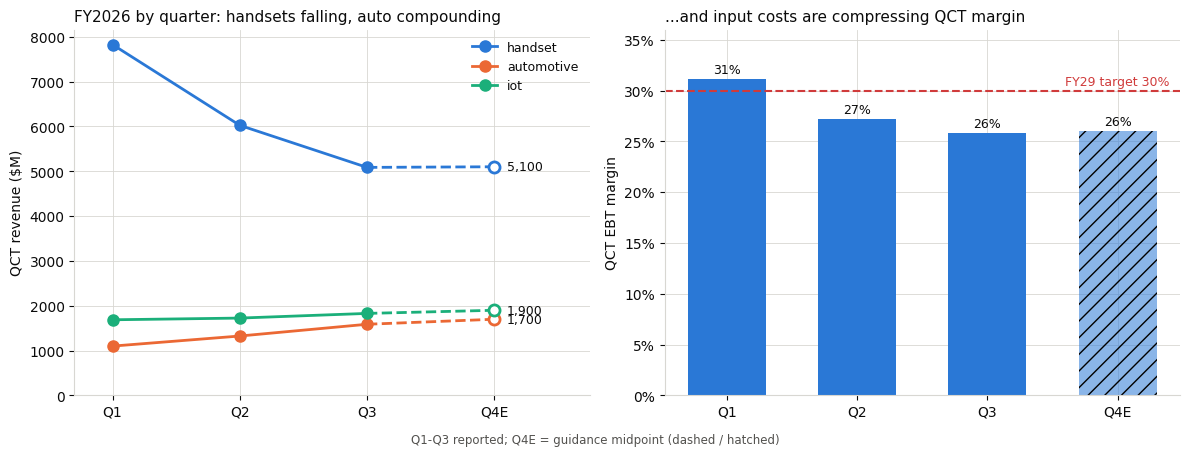

In [3]:
# The FY26 story in one chart: the three QCT lines are diverging hard.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))

x = range(4)
for seg in ['handset', 'automotive', 'iot']:
    c = SEG_COLORS[seg]
    ax1.plot(x[:3], q[seg][:3], marker='o', markersize=8, linewidth=2, color=c, label=seg)
    # Q4 is guidance, not an actual: dashed leg + hollow marker
    ax1.plot(x[2:], q[seg][2:], linestyle='--', linewidth=2, color=c)
    ax1.plot([3], [q[seg].iloc[-1]], marker='o', markersize=8, color=c,
             markerfacecolor='white', markeredgewidth=2)
    ax1.annotate(f'{q[seg].iloc[-1]:,.0f}', (3, q[seg].iloc[-1]), textcoords='offset points',
                 xytext=(9, 0), va='center', fontsize=9, color=INK)
ax1.set_xticks(list(x))
ax1.set_xticklabels(q.index)
ax1.set_ylabel('QCT revenue ($M)')
ax1.set_title('FY2026 by quarter: handsets falling, auto compounding', fontsize=11, loc='left')
ax1.legend(frameon=False, fontsize=9)
ax1.set_xlim(-0.3, 3.75)
ax1.set_ylim(0, None)

margins = (q.qct_ebt / q.qct * 100)
bars = ax2.bar(x, margins, color=SEG_COLORS['handset'], width=0.6)
bars[3].set_hatch('//')            # Q4E is guidance
bars[3].set_alpha(0.55)
ax2.axhline(30, color='#d03b3b', linestyle='--', linewidth=1.5)
ax2.text(3.4, 30.5, 'FY29 target 30%', ha='right', fontsize=9, color='#d03b3b')
for b, v in zip(bars, margins):
    ax2.text(b.get_x() + b.get_width() / 2, v + 0.6, f'{v:.0f}%', ha='center', fontsize=9, color=INK)
ax2.set_xticks(list(x))
ax2.set_xticklabels(q.index)
ax2.set_yticklabels([f'{int(t)}%' for t in ax2.get_yticks()])
ax2.set_ylabel('QCT EBT margin')
ax2.set_title('...and input costs are compressing QCT margin', fontsize=11, loc='left')
ax2.set_ylim(0, 36)
fig.text(0.5, -0.02, 'Q1-Q3 reported; Q4E = guidance midpoint (dashed / hatched)',
         ha='center', fontsize=8.5, color='#52514e')

plt.tight_layout()
plt.show()

## 3. Run-rate bridge — what each segment must actually do

The most useful thing the Q3 data adds. Read it as a scorecard against the FY29 Base targets.

In [4]:
rr = FY26_QUARTERS.loc['Q3'] * 4 / 1000        # Q3 exit run-rate, $B annualized
fy26_seg = {'handset': fy26.handset + fy26.qtl,      # model 'handset' = handsets + licensing
            'automotive': fy26.automotive, 'iot': fy26.iot, 'datacenter': 0.0}
rr_seg   = {'handset': rr.handset + rr.qtl,
            'automotive': rr.automotive, 'iot': rr.iot, 'datacenter': 0.0}

bridge = pd.DataFrame({
    'FY26E $B':      [round(fy26_seg[s], 1) for s in SEGMENTS],
    'Q3 run-rate':   [round(rr_seg[s], 1) for s in SEGMENTS],
    'FY29 Base':     [REVENUE['Base'][s] for s in SEGMENTS],
}, index=SEGMENTS)
bridge['CAGR fr FY26E'] = [
    f"{(REVENUE['Base'][s] / fy26_seg[s]) ** (1 / 3) - 1:+.0%}" if fy26_seg[s] else 'new'
    for s in SEGMENTS]
bridge['fr run-rate'] = [
    f"{(REVENUE['Base'][s] / rr_seg[s]) ** (1 / YEARS_TO_FY29) - 1:+.0%}" if rr_seg[s] else 'new'
    for s in SEGMENTS]
bridge.index.name = 'segment'
print(bridge.to_string())
print('\nAutomotive (+61% YoY) is ahead of the +21%/yr it needs.')
print('IoT (+9% YoY) needs +25%/yr and is delivering a third of that - the quiet problem.')
print('Data center starts from ~zero: mgmt guides $5B in FY27 on confirmed POs/wafer starts.')

            FY26E $B  Q3 run-rate  FY29 Base CAGR fr FY26E fr run-rate
segment                                                               
handset         29.6         25.5         20          -12%         -8%
automotive       5.7          6.4         10          +21%        +16%
iot              7.1          7.3         14          +25%        +23%
datacenter       0.0          0.0         15           new         new

Automotive (+61% YoY) is ahead of the +21%/yr it needs.
IoT (+9% YoY) needs +25%/yr and is delivering a third of that - the quiet problem.
Data center starts from ~zero: mgmt guides $5B in FY27 on confirmed POs/wafer starts.


## 4. The engine — segment SOTP → FY29 EV → PV today

For each scenario and segment: `EBITDA = revenue × margin`, `EV = EBITDA × exit multiple`. Sum to
enterprise value, subtract net debt for FY29 equity value, then discount to present and divide by
current shares.

In [5]:
def segment_table(name):
    df = pd.DataFrame({'segment': SEGMENTS})
    df['revenue_$B']    = df.segment.map(REVENUE[name])
    df['ebitda_margin'] = df.segment.map(EBITDA_MARGIN[name])
    df['ebitda_$B']     = df['revenue_$B'] * df['ebitda_margin']
    df['exit_x']        = df.segment.map(EXIT_MULTIPLE[name])
    df['EV_$B']         = df['ebitda_$B'] * df['exit_x']
    return df

def value_scenario(name):
    df = segment_table(name)
    ev = df['EV_$B'].sum()
    ebitda = df['ebitda_$B'].sum()
    equity_fy29 = ev - NET_DEBT
    price_fy29 = equity_fy29 / SHARES_OUT
    pv_price = (equity_fy29 / (1 + DISCOUNT_RATE) ** YEARS_TO_FY29) / SHARES_OUT
    return {
        'scenario': name,
        'FY29 rev $B': df['revenue_$B'].sum(),
        'FY29 EBITDA $B': round(ebitda, 1),
        'blended x': round(ev / ebitda, 1),
        'FY29 EV $B': round(ev, 0),
        'FY29 price': round(price_fy29, 0),
        'PV today': round(pv_price, 0),
        'upside': pv_price / CURRENT_PRICE - 1,
        'CAGR': (price_fy29 / CURRENT_PRICE) ** (1 / YEARS_TO_FY29) - 1,
    }

summary = pd.DataFrame([value_scenario(s) for s in ['Bear', 'Base', 'Bull']]).set_index('scenario')
summary_fmt = summary.copy()
summary_fmt['upside'] = (summary['upside'] * 100).round(0).astype(int).astype(str) + '%'
summary_fmt['CAGR'] = (summary['CAGR'] * 100).round(0).astype(int).astype(str) + '%'
summary_fmt

,FY29 rev $B,FY29 EBITDA $B,blended x,FY29 EV $B,FY29 price,PV today,upside,CAGR
scenario,,,,,,,,
Bear,43,10.9,8.7,95.0,83.0,62.0,-64%,-21%
Base,59,18.4,12.0,219.0,199.0,148.0,-13%,5%
Bull,72,24.4,16.4,399.0,367.0,274.0,61%,28%


In [6]:
# Probability-weighted fair value (PV today)
blended = sum(WEIGHTS[s] * summary.loc[s, 'PV today'] for s in WEIGHTS)
print(f'Probability-weighted PV (25/50/25): ${blended:.0f}/sh  '
      f'({blended / CURRENT_PRICE - 1:+.0%} vs ${CURRENT_PRICE:.2f})')
print(f'\nJune 2026 run, for comparison: $165/sh vs a $250.00 price (-34%).')
print('The fair-value estimate moved ~4%; the price moved -32%. The gap closed from')
print('the price side, not the model side.')

Probability-weighted PV (25/50/25): $158/sh  (-7% vs $170.48)

June 2026 run, for comparison: $165/sh vs a $250.00 price (-34%).
The fair-value estimate moved ~4%; the price moved -32%. The gap closed from
the price side, not the model side.


## 5. Sum-of-the-parts detail (per scenario)

In [7]:
for s in ['Bear', 'Base', 'Bull']:
    print(f'\n===== {s} =====')
    t = segment_table(s).copy()
    t['ebitda_margin'] = (t['ebitda_margin'] * 100).round(0).astype(int).astype(str) + '%'
    t['ebitda_$B'] = t['ebitda_$B'].round(2)
    print(t.to_string(index=False))


===== Bear =====
   segment  revenue_$B ebitda_margin  ebitda_$B  exit_x  EV_$B
   handset          16           32%       5.12       7  35.84
automotive           8           22%       1.76      10  17.60
       iot          10           24%       2.40      10  24.00
datacenter           9           18%       1.62      11  17.82

===== Base =====
   segment  revenue_$B ebitda_margin  ebitda_$B  exit_x  EV_$B
   handset          20           38%       7.60       8   60.8
automotive          10           28%       2.80      13   36.4
       iot          14           30%       4.20      13   54.6
datacenter          15           25%       3.75      18   67.5

===== Bull =====
   segment  revenue_$B ebitda_margin  ebitda_$B  exit_x  EV_$B
   handset          23           40%       9.20      10  92.00
automotive          13           30%       3.90      16  62.40
       iot          16           33%       5.28      18  95.04
datacenter          20           30%       6.00      25 150.00


## 6. Charts

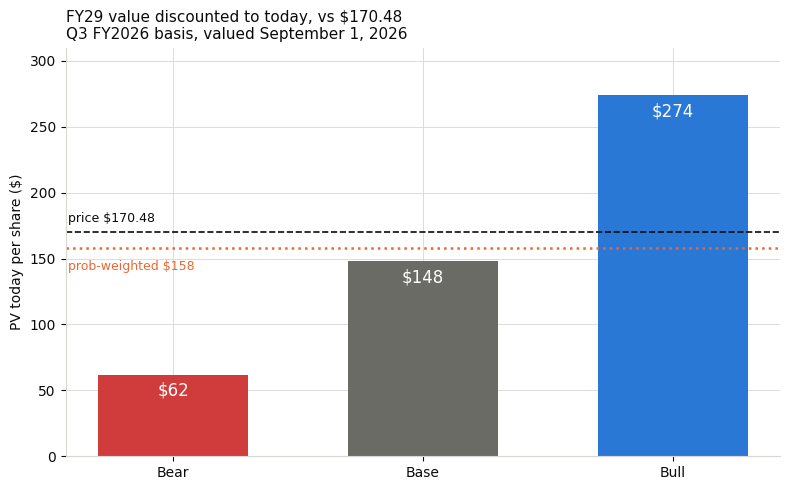

In [8]:
# PV today per share by scenario vs current price
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(summary.index, summary['PV today'], width=0.6,
              color=[SCEN_COLORS[s] for s in summary.index])
ax.axhline(CURRENT_PRICE, color=INK, linestyle='--', linewidth=1.2)
ax.text(-0.42, CURRENT_PRICE + 7, f'price ${CURRENT_PRICE:.2f}', ha='left', fontsize=9)
ax.axhline(blended, color='#eb6834', linestyle=':', linewidth=1.8)
ax.text(-0.42, blended - 17, f'prob-weighted ${blended:.0f}', ha='left', color='#eb6834', fontsize=9)
# labels inside the bars, so they never collide with the reference lines
for b, v in zip(bars, summary['PV today']):
    ax.text(b.get_x() + b.get_width() / 2, v - 16, f'${v:.0f}',
            ha='center', fontsize=12, color='white')
ax.set_ylabel('PV today per share ($)')
ax.set_title(f'FY29 value discounted to today, vs ${CURRENT_PRICE:.2f}'
             f'\nQ3 FY2026 basis, valued {VALUATION_DATE}', fontsize=11, loc='left')
ax.set_ylim(0, 310)
plt.tight_layout()
plt.show()

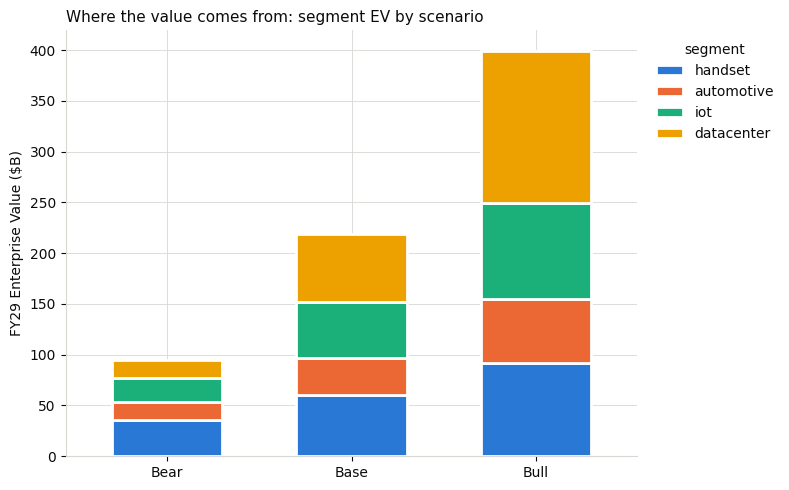

Data-center share of FY29 EV: {'Bear': '19%', 'Base': '31%', 'Bull': '38%'}


In [9]:
# Segment EV contribution (FY29) - stacked by scenario
ev_by_seg = pd.DataFrame({s: segment_table(s).set_index('segment')['EV_$B']
                          for s in ['Bear', 'Base', 'Bull']}).T
ax = ev_by_seg.plot(kind='bar', stacked=True, figsize=(8, 5), width=0.6,
                    color=[SEG_COLORS[s] for s in ev_by_seg.columns],
                    edgecolor='white', linewidth=2)   # 2px surface gap between segments
ax.set_ylabel('FY29 Enterprise Value ($B)')
ax.set_title('Where the value comes from: segment EV by scenario', fontsize=11, loc='left')
ax.legend(title='segment', bbox_to_anchor=(1.01, 1), frameon=False)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print('Data-center share of FY29 EV:',
      {s: f"{ev_by_seg.loc[s, 'datacenter'] / ev_by_seg.loc[s].sum():.0%}" for s in ev_by_seg.index})

## 7. Sensitivity

The valuation is dominated by the **discount rate** and the **data-center exit multiple**.
Both tables below flex the **Base** scenario.

In [10]:
# Base FY29 equity value, fixed; vary discount rate -> PV today / share
base_ev = segment_table('Base')['EV_$B'].sum()
base_equity = base_ev - NET_DEBT
rates = [0.06, 0.08, 0.10, 0.12, 0.14]
pv = {f'{r:.0%}': round((base_equity / (1 + r) ** YEARS_TO_FY29) / SHARES_OUT, 0) for r in rates}
pd.DataFrame.from_dict(pv, orient='index',
                       columns=['Base PV today / share ($)']).rename_axis('discount rate')

,Base PV today / share ($)
discount rate,
6%,166.0
8%,157.0
10%,148.0
12%,140.0
14%,133.0


In [11]:
# 2-D sensitivity: data-center exit multiple (rows) x discount rate (cols) -> Base PV today / share
dc_mults = [8, 12, 16, 18, 22, 26]
base = segment_table('Base').set_index('segment')
ex_dc_ev = base['EV_$B'].sum() - base.loc['datacenter', 'EV_$B']   # EV of non-DC segments
dc_ebitda = base.loc['datacenter', 'ebitda_$B']
grid = {}
for r in rates:
    grid[f'{r:.0%}'] = [round(((ex_dc_ev + dc_ebitda * m - NET_DEBT)
                               / (1 + r) ** YEARS_TO_FY29) / SHARES_OUT, 0) for m in dc_mults]
sens = pd.DataFrame(grid, index=[f'{m}x' for m in dc_mults]).rename_axis('data-center exit x')
print(f'Base PV today / share ($). Current price ${CURRENT_PRICE:.2f}; '
      f'base case is 18x at 10% discount.\n')
print(sens.to_string())

Base PV today / share ($). Current price $170.48; base case is 18x at 10% discount.

                       6%     8%    10%    12%    14%
data-center exit x                                   
8x                  137.0  129.0  122.0  115.0  109.0
12x                 148.0  140.0  132.0  125.0  119.0
16x                 160.0  151.0  143.0  135.0  128.0
18x                 166.0  157.0  148.0  140.0  133.0
22x                 178.0  168.0  159.0  150.0  142.0
26x                 189.0  179.0  169.0  160.0  151.0


## 8. EPS cross-check — is the Base case consistent with management's >$18 FY29 EPS?

This is the check the June version of this model claimed to do but didn't. It matters: it shows that
"Base = management targets" is true of **revenue**, not of **margins**.

In [12]:
def ebitda_to_eps(ebitda):
    return (ebitda - FY29_D_AND_A - NET_INTEREST_FY29) * (1 - NON_GAAP_TAX_RATE) / FY29_SHARES

def eps_to_ebitda(eps):
    return eps * FY29_SHARES / (1 - NON_GAAP_TAX_RATE) + FY29_D_AND_A + NET_INTEREST_FY29

base_ebitda = segment_table('Base')['ebitda_$B'].sum()   # unrounded, to match model.py
base_rev = segment_table('Base')['revenue_$B'].sum()
mgmt_ebitda = eps_to_ebitda(MGMT_FY29_EPS)

check = pd.DataFrame({
    'FY29 EBITDA $B': [round(base_ebitda, 1), round(mgmt_ebitda, 1)],
    'implied margin': [f'{base_ebitda / base_rev:.0%}', f'{mgmt_ebitda / base_rev:.0%}'],
    'implied FY29 EPS': [f'${ebitda_to_eps(base_ebitda):.2f}', f'>${MGMT_FY29_EPS:.2f}'],
}, index=["this model's Base", "mgmt's >$18 EPS target implies"])
print(check.to_string())

gap = mgmt_ebitda - base_ebitda
print(f'\nGap: this model runs ${gap:.1f}B ({1 - base_ebitda / mgmt_ebitda:.0%}) below the')
print('profitability mgmt\'s own EPS target implies. Note that mgmt\'s implied 40% EBITDA margin')
print(f'would be a large expansion from the {fy26_ebitda / fy26.total:.0%} QCOM is running at in FY26,')
print('so the scepticism is defensible - but it should be stated, not buried in a label.')

# What the Base multiples give if mgmt is right on margins too (revenue-weighted allocation)
rev_share = {s: REVENUE['Base'][s] / base_rev for s in SEGMENTS}
ev_mgmt = sum(mgmt_ebitda * rev_share[s] * EXIT_MULTIPLE['Base'][s] for s in SEGMENTS)
pv_mgmt = ((ev_mgmt - NET_DEBT) / (1 + DISCOUNT_RATE) ** YEARS_TO_FY29) / SHARES_OUT
print(f'\nIf mgmt hits BOTH revenue and EPS, at Base exit multiples: '
      f'~${pv_mgmt:.0f}/sh ({pv_mgmt / CURRENT_PRICE - 1:+.0%})')

                                FY29 EBITDA $B implied margin implied FY29 EPS
this model's Base                         18.4            31%           $13.69
mgmt's >$18 EPS target implies            23.4            40%          >$18.00

Gap: this model runs $5.1B (22%) below the
profitability mgmt's own EPS target implies. Note that mgmt's implied 40% EBITDA margin
would be a large expansion from the 33% QCOM is running at in FY26,
so the scepticism is defensible - but it should be stated, not buried in a label.

If mgmt hits BOTH revenue and EPS, at Base exit multiples: ~$200/sh (+18%)


## 9. Investor Day comparison — Nov 2024 vs. June 2026 (FY29 targets)

| FY2029 target | Nov 2024 | June 2026 | Change |
|---|---:|---:|:--|
| **Non-handset revenue** | **$22B** | **$40B** | **+82%** |
| Automotive | $8B | $10B | +25% |
| IoT (total) | $14B | $14B | flat (re-segmented) |
| Data center | *not a stated FY29 line* | **>$15B** | **new pillar** |
| Non-GAAP EPS | ~$18 | >$18 | maintained |
| Mix goal | 50/50 handset vs auto+IoT (2030) | ~⅓ / ⅓ / ⅓ (handset / auto+IoT / data center) | data center added |
| QCT / QTL op margin | 30% / 70% | 30% / 70% | reaffirmed |

**Reaffirmed at the Q3 FY2026 print (July 29, 2026)**, with two additions: an interim **$5B FY2027**
data-center milestone backed by purchase orders and wafer starts, and non-handset growth accelerating
from **24% in FY26 to >60% in FY27**.

The near-doubling of non-handset revenue ($22B → $40B) against a barely-changed EPS target (~$18 →
>$18) implies the incremental data-center revenue carries **lower incremental margin** than the legacy
mix — which is why this model treats the data-center exit multiple, not just its revenue, as the key
swing variable.

---

*Source: [Q3 FY2026 earnings release](https://s204.q4cdn.com/645488518/files/doc_financials/2026/q3/FY2026-3rd-Quarter-Earnings-Release.pdf).
Not investment advice.*